
# Netflix Content Analytics

## Problem Statement

Netflix offers a large and diverse collection of movies and TV shows across different countries, genres, ratings, and release years. Analyzing this content can help identify patterns in content distribution, audience preferences, regional availability, and content growth over time.

## Objective

This project aims to analyze Netflix content using Python, Pandas, NumPy, Matplotlib, and Seaborn to uncover trends in content type, ratings, genres, countries, release patterns, and content additions, and generate actionable business insights to support content acquisition and content strategy decisions.

## Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

# 1. Dataset Overview

## Objective

Understand the structure, dimensions, and features of the Netflix dataset before beginning data validation, cleaning, and exploratory data analysis.

## 1.1 Data Loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../Data/netflix_titles.csv")

## 1.2 Dataset Preview

Preview the first few records to understand the structure and type of information contained in the dataset.

In [3]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 1.3 Dataset Dimensions

In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (8807, 12)


## 1.4 Dataset Columns

In [5]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

## 1.5 Dataset Information

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


## 1.6 Dataset Description

The dataset contains information about Netflix movies and TV shows, including content type, title, director, cast, country, date added, release year, rating, duration, genre, and description.

The dataset contains 8,807 Netflix titles and 12 attributes.

# 2. Data Validation & Preparation

## Objective

Validate and prepare the dataset by checking missing values, duplicate records, data types, invalid values, and date and duration fields before performing exploratory data analysis.

## 2.1 Missing Value Analysis

In [7]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

### Missing Value Summary

The dataset contains missing values in several descriptive columns such as director, cast, country, date_added, rating, and duration. These missing values will be handled according to the requirements of each analysis rather than removing large numbers of records unnecessarily.

## 2.2 Duplicate Record Analysis

In [8]:
df.duplicated().sum()

np.int64(0)

### Duplicate Record Summary

Duplicate records were checked to ensure that the same Netflix title was not unintentionally repeated in the dataset.

## 2.3 Data Type Validation

In [9]:
df.dtypes

show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

## 2.4 Identify Invalid Rating Values

Some records contain duration values such as `74 min`, `84 min`, and `66 min` in the `rating` column. These values are not audience ratings and need to be moved to the `duration` column.

In [10]:
invalid_rating_mask = df["rating"].astype(str).str.contains("min", na=False)

df.loc[invalid_rating_mask, ["title", "rating", "duration"]]

,title,rating,duration
5541,Louis C.K. 2017,74 min,NaN
5794,Louis C.K.: Hilarious,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,66 min,NaN


## 2.5 Correct Misplaced Duration Values

The incorrectly stored duration values are moved from the `rating` column to the `duration` column, and the invalid rating values are replaced with missing values.

In [11]:
df.loc[invalid_rating_mask, "duration"] = df.loc[invalid_rating_mask, "rating"]
df.loc[invalid_rating_mask, "rating"] = np.nan

### Verify Corrected Values

In [12]:
df.loc[invalid_rating_mask, ["title", "rating", "duration"]]

,title,rating,duration
5541,Louis C.K. 2017,NaN,74 min
5794,Louis C.K.: Hilarious,NaN,84 min
5813,Louis C.K.: Live at the Comedy Store,NaN,66 min


## 2.6 Date Conversion

The `date_added` column is converted from text to datetime format so that year-based and time-based analysis can be performed.

In [13]:
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")

df["date_added"].dtype

dtype('<M8[ns]')

## 2.7 Data Preparation Summary

The dataset has been validated for missing values and duplicate records. Invalid duration values found in the rating column were corrected, and the `date_added` column was converted to datetime format.

The prepared dataset is now ready for exploratory data analysis.

# 3. Exploratory Data Analysis

## Objective

Explore the distribution and characteristics of Netflix content to identify patterns and trends across content type, ratings, release years, countries, genres, duration, and content additions.

## 3.1 Content Type Distribution

### Objective

Analyze the distribution of movies and TV shows in the Netflix catalog.

In [14]:
content_type = df["type"].value_counts()

content_type

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

### Content Type Percentage Distribution

In [15]:
content_type_percentage = df["type"].value_counts(normalize=True) * 100

content_type_percentage

type
Movie      69.615079
TV Show    30.384921
Name: proportion, dtype: float64

### Visualization: Content Type Distribution

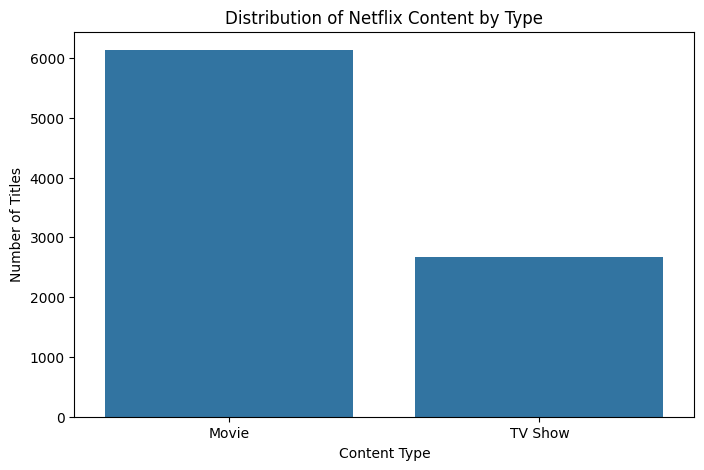

In [16]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=content_type.index,
    y=content_type.values
)

plt.title("Distribution of Netflix Content by Type")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.show()

### Insight: Content Type

Movies represent the larger share of the Netflix catalog, while TV shows account for a smaller but significant portion of the available content.

### Business Recommendation

Netflix can maintain a balanced content strategy while evaluating whether additional investment in TV shows could strengthen long-term viewer engagement and retention.

## 3.2 Ratings Analysis

### Objective

Analyze the distribution of content across different audience ratings to understand the types of content available on Netflix.

In [17]:
rating_counts = df["rating"].value_counts()

rating_counts

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

### Visualization: Rating Distribution

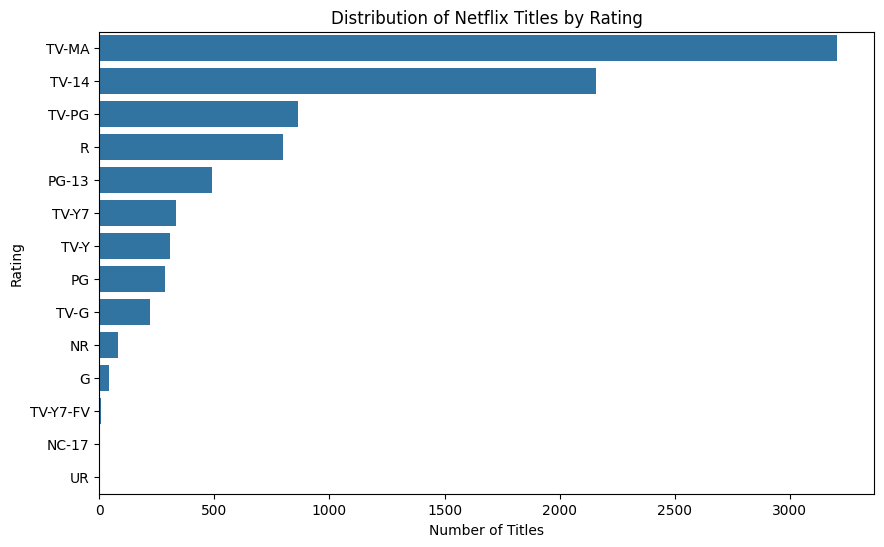

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=rating_counts.values,
    y=rating_counts.index
)

plt.title("Distribution of Netflix Titles by Rating")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")

plt.show()

### Insight: Content Ratings

TV-MA is the most common rating in the Netflix dataset, followed by TV-14 and TV-PG. This indicates that a large portion of the Netflix catalog is targeted toward teenage and adult audiences.

### Business Recommendation

Netflix can continue maintaining a diverse content portfolio across audience groups while using rating trends to guide audience-focused content acquisition and production decisions.

## 3.3 Release Year Analysis

### Objective

Analyze the release years of Netflix titles to understand the balance between recent and older content in the catalog.

In [19]:
release_year_counts = df["release_year"].value_counts().sort_index()

release_year_counts.tail(20)

release_year
2002      51
2003      61
2004      64
2005      80
2006      96
2007      88
2008     136
2009     152
2010     194
2011     185
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, dtype: int64

### Visualization: Netflix Titles by Release Year

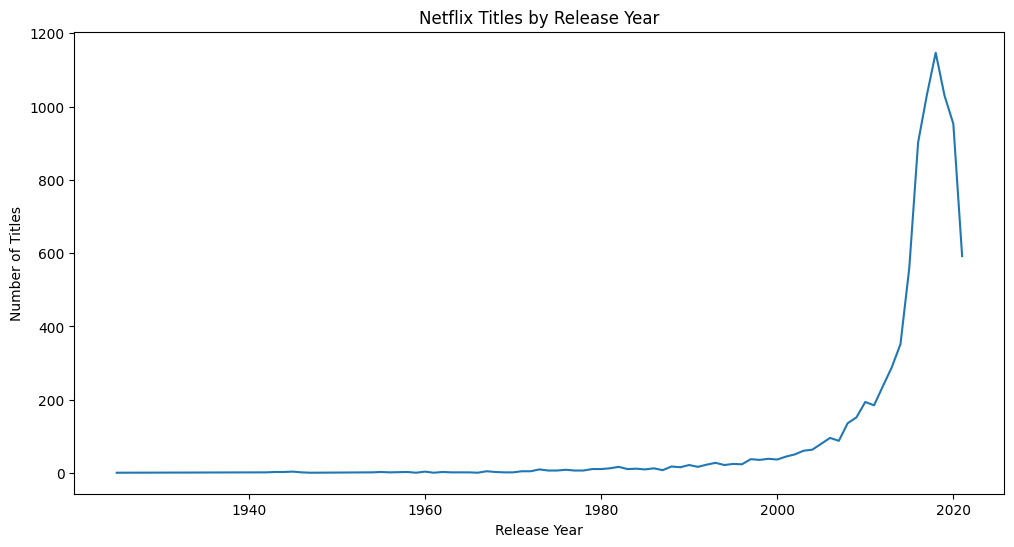

In [20]:
plt.figure(figsize=(12, 6))

plt.plot(
    release_year_counts.index,
    release_year_counts.values
)

plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.show()

### Insight: Release Year

The Netflix catalog contains content released across many decades, with a strong concentration of titles from more recent years.

### Business Recommendation

Netflix can continue investing in recent content while maintaining selected older titles that have long-term audience value and contribute to catalog diversity.

## 3.4 Country Analysis

### Objective

Analyze the countries associated with Netflix titles to understand regional content distribution and identify major content-producing markets.

In [21]:
country_df = df[["title", "country"]].dropna().copy()

country_df["country"] = country_df["country"].str.split(",")

country_df = country_df.explode("country")

country_df["country"] = country_df["country"].str.strip()

country_counts = country_df["country"].value_counts()

country_counts.head(10)

country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64

### Visualization: Top 10 Countries by Number of Netflix Titles

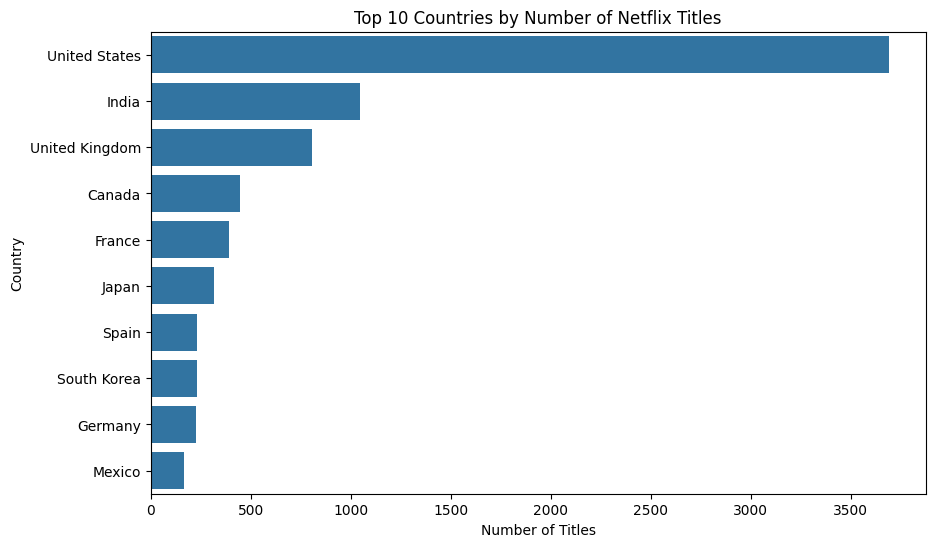

In [22]:
top_countries = country_counts.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Number of Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.show()

### Insight: Regional Content Distribution

The United States and India are among the largest content-producing markets represented in the Netflix catalog, followed by several other major international markets.

### Business Recommendation

Netflix can continue strengthening its presence in major content-producing markets while expanding regional and localized content strategies in underrepresented markets with growth potential.

## 3.5 Genre Analysis

### Objective

Analyze the distribution of genres to identify the most common content categories available on Netflix.

In [23]:
genre_df = df[["title", "listed_in"]].dropna().copy()

genre_df["listed_in"] = genre_df["listed_in"].str.split(",")

genre_df = genre_df.explode("listed_in")

genre_df["listed_in"] = genre_df["listed_in"].str.strip()

genre_counts = genre_df["listed_in"].value_counts()

genre_counts.head(10)

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

### Visualization: Top 10 Netflix Genres

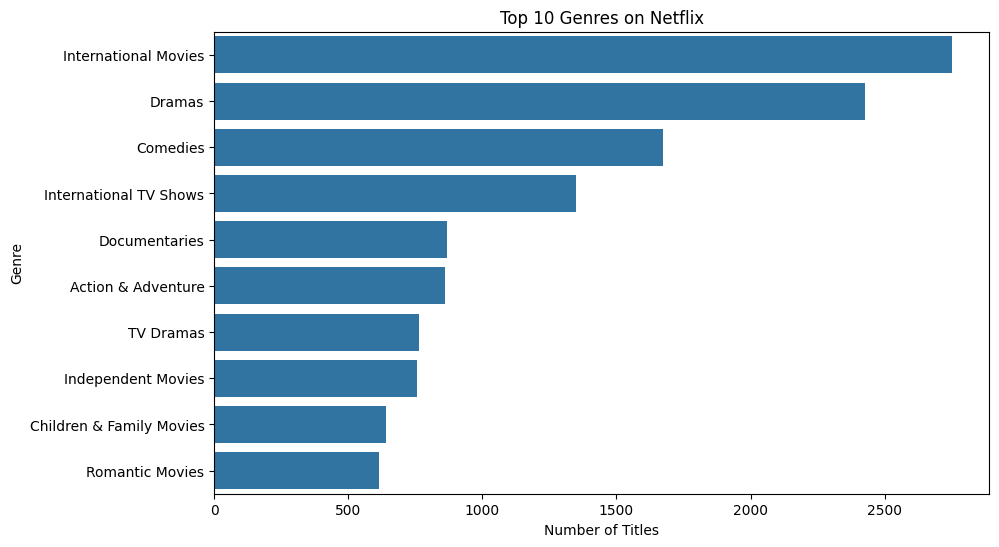

In [24]:
top_genres = genre_counts.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.show()

### Insight: Genre Distribution

Netflix has a broad genre portfolio, with several entertainment-focused categories accounting for a large share of the catalog.

### Business Recommendation

Netflix can use genre-level demand patterns to guide content acquisition and production while maintaining a diverse portfolio to serve different audience interests.

## 3.6 Content Added to Netflix Over Time

### Objective

Analyze when titles were added to Netflix to understand content growth and changes in the platform's catalog over time.

In [25]:
added_year = df["date_added"].dt.year.value_counts().sort_index()

added_year

date_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      10
2014.0      23
2015.0      73
2016.0     418
2017.0    1164
2018.0    1625
2019.0    1999
2020.0    1878
2021.0    1498
Name: count, dtype: int64

### Visualization: Netflix Titles Added Over Time

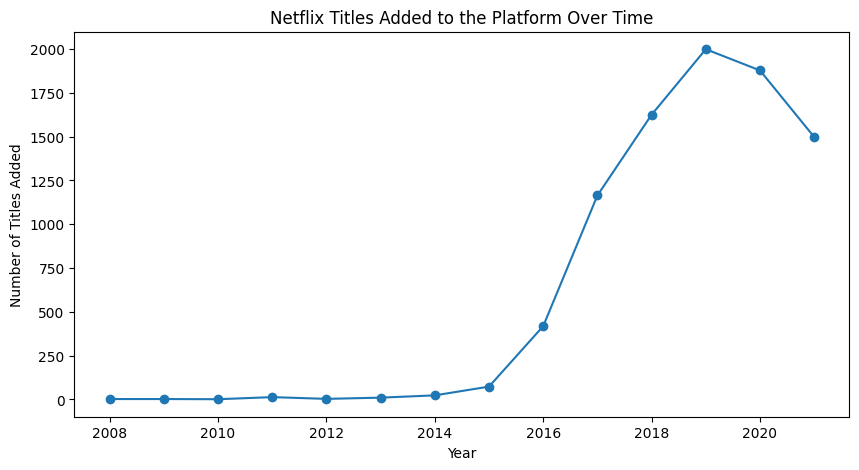

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(
    added_year.index,
    added_year.values,
    marker="o"
)

plt.title("Netflix Titles Added to the Platform Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Titles Added")

plt.show()

### Insight: Content Addition Trend

The number of titles added to Netflix changed significantly over time, reflecting periods of increased content expansion and changes in the platform's content strategy.

### Business Recommendation

Netflix can monitor content addition trends alongside audience engagement to determine the optimal pace and mix of future content acquisitions.

## 3.7 Movie Duration Analysis

### Objective

Analyze movie duration to understand the typical length of movies available on Netflix.

In [27]:
movie_duration = df[df["type"] == "Movie"]["duration"].dropna().copy()

movie_duration = movie_duration.str.extract(r"(\d+)")[0].astype(float)

movie_duration.describe()

count    6131.000000
mean       99.564998
std        28.289504
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: 0, dtype: float64

### Visualization: Movie Duration Distribution

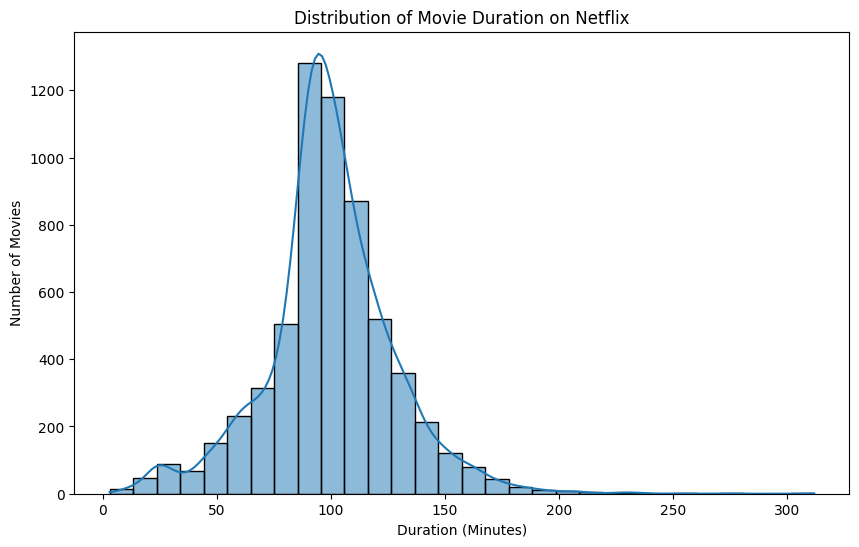

In [28]:
plt.figure(figsize=(10, 6))

sns.histplot(
    movie_duration,
    bins=30,
    kde=True
)

plt.title("Distribution of Movie Duration on Netflix")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")

plt.show()

### Insight: Movie Duration

Netflix movies cover a wide range of durations, with a strong concentration around typical feature-film lengths.

### Business Recommendation

Netflix can maintain variety in movie length while considering audience viewing behavior when evaluating future movie acquisitions and productions.


## 3.8 TV Show Season Analysis

### Objective

Analyze the number of seasons in Netflix TV shows to understand the structure and depth of serialized content.

In [29]:
tv_seasons = df[df["type"] == "TV Show"]["duration"].dropna().copy()

tv_seasons = tv_seasons.str.extract(r"(\d+)")[0].astype(float)

tv_seasons.value_counts().sort_index().head(15)

0
1.0     1793
2.0      425
3.0      199
4.0       95
5.0       65
6.0       33
7.0       23
8.0       17
9.0        9
10.0       7
11.0       2
12.0       2
13.0       3
15.0       2
17.0       1
Name: count, dtype: int64

### Visualization: TV Show Seasons Distribution

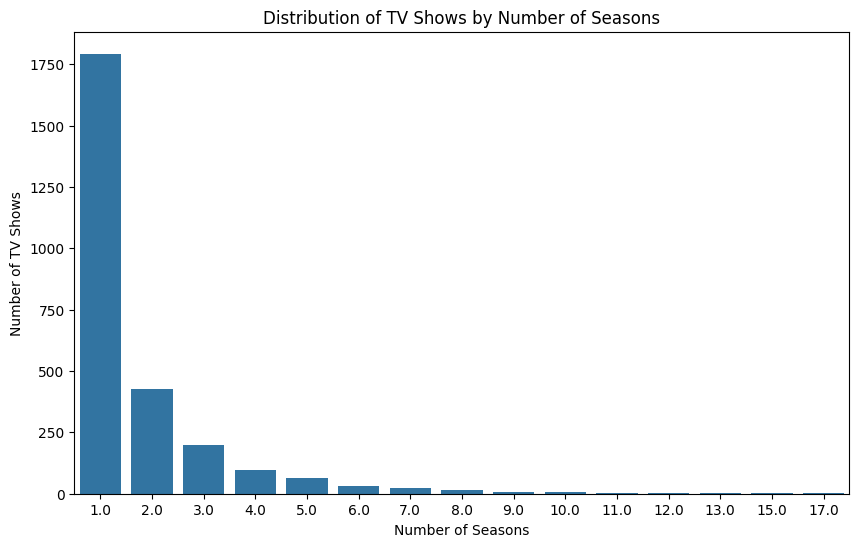

In [30]:
plt.figure(figsize=(10, 6))

sns.countplot(
    x=tv_seasons
)

plt.title("Distribution of TV Shows by Number of Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")

plt.show()

### Insight: TV Show Seasons

A large proportion of Netflix TV shows have relatively few seasons, indicating that many series have shorter content lifecycles compared with long-running television programs.


### Business Recommendation

Netflix can evaluate viewer engagement and completion patterns to identify which shows have potential for longer-term continuation and which formats perform better as shorter series.

# 4. Comparative Analysis

## Objective

Compare multiple content attributes to identify deeper relationships and patterns that cannot be observed by analyzing individual variables separately.

## 4.1 Movies vs TV Shows by Release Year

In [31]:
type_release_year = pd.crosstab(
    df["release_year"],
    df["type"]
)

type_release_year.tail(20)

type,Movie,TV Show
release_year,,
2002,44,7
2003,51,10
2004,55,9
2005,67,13
2006,82,14
2007,74,14
2008,113,23
2009,118,34
2010,154,40


### Visualization: Movies vs TV Shows by Release Year

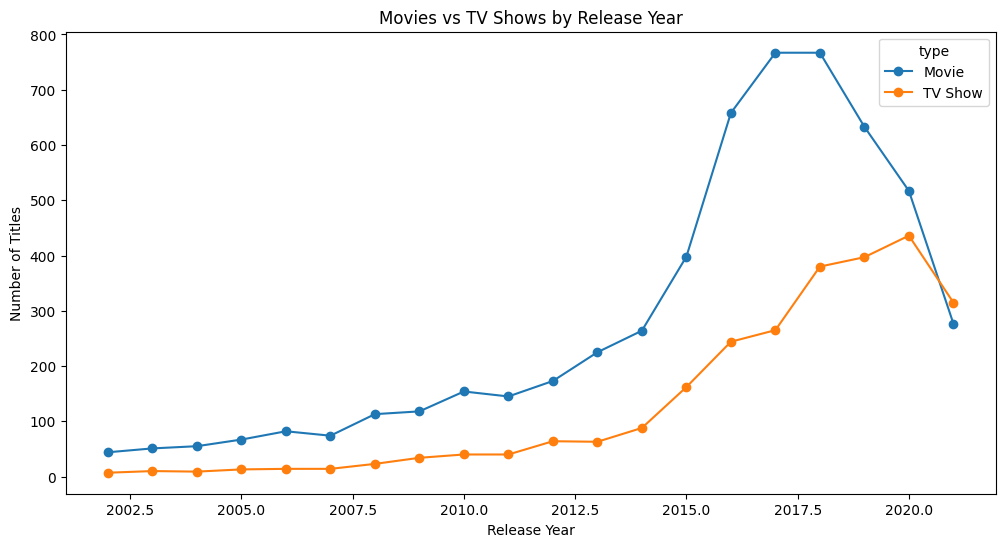

In [32]:
type_release_year.tail(20).plot(
    figsize=(12, 6),
    marker="o"
)

plt.title("Movies vs TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.show()

### Insight: Content Type and Release Year

The distribution of movies and TV shows varies across release years, reflecting changes in Netflix's catalog composition and the broader growth of streaming-based television content.

### Business Recommendation

Netflix can use content-type trends across release periods to balance investments between movies and serialized TV content according to audience demand.

## 4.2 Movies vs TV Shows by Rating

In [33]:
type_rating = pd.crosstab(
    df["rating"],
    df["type"]
)

type_rating

type,Movie,TV Show
rating,,
G,41,0
NC-17,3,0
NR,75,5
PG,287,0
PG-13,490,0
R,797,2
TV-14,1427,733
TV-G,126,94
TV-MA,2062,1145


### Visualization: Content Type by Rating

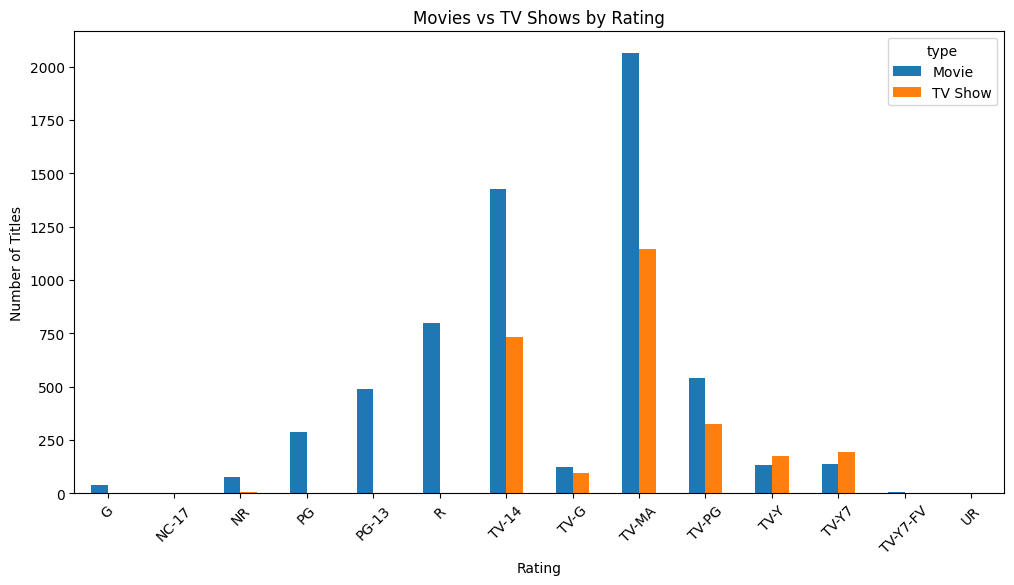

In [34]:
type_rating.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Movies vs TV Shows by Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.show()

### Insight: Content Type and Rating

The rating distribution differs between movies and TV shows, indicating that the two content types serve somewhat different audience segments.

### Business Recommendation

Netflix can use the relationship between content type and audience rating to create more targeted acquisition and production strategies for different viewer segments.

## 4.3 Content Growth by Type

### Objective

Compare the number of movies and TV shows added to Netflix over time.

In [35]:
content_added_by_type = pd.crosstab(
    df["date_added"].dt.year,
    df["type"]
)

content_added_by_type

type,Movie,TV Show
date_added,,
2008.0,1,1
2009.0,2,0
2010.0,1,0
2011.0,13,0
2012.0,3,0
2013.0,6,4
2014.0,19,4
2015.0,56,17
2016.0,253,165


### Visualization: Content Added by Type Over Time

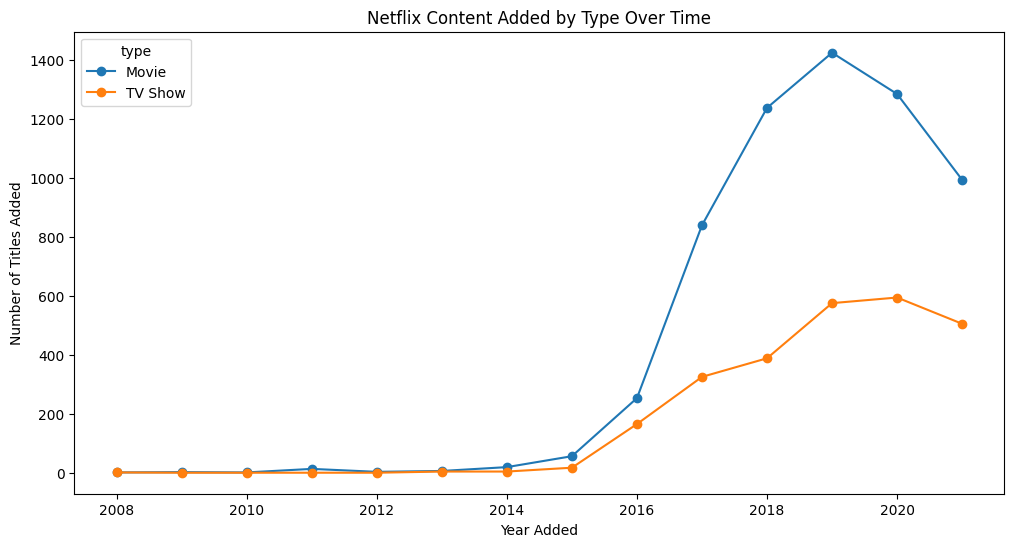

In [36]:
content_added_by_type.plot(
    figsize=(12, 6),
    marker="o"
)

plt.title("Netflix Content Added by Type Over Time")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles Added")

plt.show()

### Insight: Content Growth by Type

The number of movies and TV shows added to Netflix has varied over time, providing insight into changes in the platform's content acquisition strategy.

### Business Recommendation

Netflix can monitor the changing contribution of movies and TV shows to overall catalog growth when planning future acquisition budgets and original content investments.


# 5. Key Business Insights

## 5.1 Content Mix

Movies represent the larger portion of the Netflix catalog, while TV shows form a smaller but important part of the content portfolio.

## 5.2 Audience Insights

TV-MA and TV-14 are among the most common ratings, indicating strong representation of content targeted toward mature and teenage audiences.

## 5.3 Regional Insights

The United States and India are major content-producing markets represented in the Netflix catalog, while several other international markets also contribute significantly.

## 5.4 Genre Insights

Netflix maintains a broad range of genres, allowing the platform to serve different audience preferences and viewing interests.

## 5.5 Content Growth

The number of titles added to Netflix has changed considerably over time, reflecting shifts in content acquisition and platform expansion.

## 5.6 Content Format

Movies cover a broad range of durations, while many TV shows contain relatively few seasons, indicating a strong presence of shorter serialized content.

# 6. Business Recommendations

## 6.1 Content Acquisition

Use content type, genre, rating, and release trends to identify opportunities for future acquisitions.

## 6.2 Regional Expansion

Continue investing in regional and localized content, particularly in markets with strong representation and potential audience growth.

## 6.3 Audience Targeting

Use rating and genre distributions to develop content strategies for different audience segments.

## 6.4 Content Mix

Maintain a balanced portfolio of movies and TV shows while monitoring changing audience preferences.

## 6.5 Long-Term Content Strategy

Combine historical content trends with audience engagement data to determine which genres, formats, and regions should receive greater investment.

# 7. Conclusion

This project analyzed the Netflix content catalog using Python, Pandas, NumPy, Matplotlib, and Seaborn.

The analysis explored content type, audience ratings, release years, countries, genres, movie duration, TV show seasons, and content addition trends.

The findings highlight the importance of maintaining a diverse content portfolio, understanding regional content patterns, targeting different audience segments, and continuously evaluating content acquisition strategies.

These insights can support data-driven decisions related to content acquisition, regional expansion, audience targeting, and overall content strategy.